# Gradient boosting regression of cortical bone modulus from chemical composition
E: modulus in GPa

Ca: calcium concentration in gm/gm

Vf: bone volume fraction (1-porosity)

Model: `sklearn.ensemble.GradientBoostingRegressor` — an additive ensemble of shallow regression trees, no physical form assumed

E ≈ F_M(Ca, Vf) = F_0 + ν·[h_1(Ca, Vf) + h_2(Ca, Vf) + … + h_M(Ca, Vf)]

F_0: mean E of the training data; h_m: regression tree fit to the residuals of the previous m−1 trees; ν: learning rate; M: number of trees

Hyperparameters (M, ν, tree depth, min samples per leaf, subsample fraction) are chosen by 5-fold cross-validation on the training data only

This version widens the grid for the number of trees to M = 20, 30, 40, 50, 75, 100, 200, 400 (previous notebook: 50, 100, 200, 400), so cross-validation can pick fewer than 50 trees

An extra cell shows how CV RMSE changes across the grid values for tree depth (max_depth) and leaf limit (min_samples_leaf)

Data to be imported is 'bone_composition_modulus_final'

Code is written to split the data into 75% fitting / 25% test (same shuffle and split as the Currey notebook)


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, KFold

DATA = 'bone_composition_modulus_final.csv'
SEED, TEST_FRAC = 0, 0.25

GRID = {'n_estimators': [20, 30, 40, 50, 75, 100, 200, 400],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'max_depth': [1, 2, 3, 4],
        'min_samples_leaf': [1, 5, 10],
        'subsample': [0.7, 1.0]}

def metrics(obs, pred):
    r = obs - pred
    return dict(R2=1 - (r ** 2).sum() / ((obs - obs.mean()) ** 2).sum(),
                RMSE=np.sqrt((r ** 2).mean()), MAE=np.abs(r).mean(), bias=r.mean())

def fit_split(d, seed):
    idx = np.random.default_rng(seed).permutation(len(d))   # shuffle before splitting
    n_test = int(round(TEST_FRAC * len(d)))
    te, tr = d.iloc[idx[:n_test]], d.iloc[idx[n_test:]]
    X = lambda s: np.column_stack([s.Ca_mg_g.values / 1000, s.Vf.values])
    search = GridSearchCV(GradientBoostingRegressor(random_state=seed), GRID,
                          cv=KFold(5, shuffle=True, random_state=seed),
                          scoring='neg_root_mean_squared_error', n_jobs=-1)
    search.fit(X(tr), tr.E_GPa.values)                       # tuning uses training data only
    return tr, te, search, X

d = pd.read_csv(DATA).dropna(subset=['Ca_mg_g', 'Vf', 'E_GPa']).reset_index(drop=True)
tr, te, search, X = fit_split(d, SEED)
gbr, p = search.best_estimator_, search.best_params_
pred_tr, pred_te = gbr.predict(X(tr)), gbr.predict(X(te))
m_tr, m_te = metrics(tr.E_GPa.values, pred_tr), metrics(te.E_GPa.values, pred_te)

print(f'Data: {DATA}, n = {len(d)}: train {len(tr)}, test {len(te)}, shuffle seed {SEED}')
for n, v in p.items(): print(f'  {n} = {v}')
print(f'  5-fold CV RMSE = {-search.best_score_:.3f} ± {search.cv_results_["std_test_score"][search.best_index_]:.2g} GPa (training data)')
print(f'  feature importance: Ca = {gbr.feature_importances_[0]:.3f}, Vf = {gbr.feature_importances_[1]:.3f}')
print(pd.DataFrame({'train': m_tr, 'test': m_te}).round(3).to_string())

Data: bone_composition_modulus_final.csv, n = 369: train 277, test 92, shuffle seed 0
  learning_rate = 0.2
  max_depth = 2
  min_samples_leaf = 10
  n_estimators = 20
  subsample = 0.7
  5-fold CV RMSE = 3.935 ± 0.35 GPa (training data)
  feature importance: Ca = 0.693, Vf = 0.307
      train   test
R2    0.801  0.740
RMSE  3.474  4.092
MAE   2.670  3.023
bias  0.030  0.279


# CV RMSE by learning rate and number of trees
Best 5-fold CV RMSE (GPa, training data) over the other settings, for each learning rate × number of trees

In [2]:
cv = pd.DataFrame(search.cv_results_).assign(RMSE=lambda r: -r.mean_test_score)
tab = cv.pivot_table(index='param_learning_rate', columns='param_n_estimators', values='RMSE', aggfunc='min')
tab.index.name, tab.columns.name = 'learning_rate', 'n_estimators'
print(tab.round(3).to_string())
tab.to_csv('gbr_cv20_dl_cv_table.csv')

n_estimators     20     30     40     50     75     100    200    400
learning_rate                                                        
0.01           6.761  6.348  5.992  5.674  5.070  4.680  4.119  4.006
0.05           4.653  4.281  4.139  4.069  4.023  4.025  4.030  4.103
0.10           4.063  4.045  4.026  4.026  4.051  4.053  4.084  4.102
0.20           3.935  3.988  3.983  3.999  4.078  4.099  4.147  4.170


# CV RMSE by tree depth and leaf limit
Left table / heatmap: best 5-fold CV RMSE (GPa, training data) for each max_depth × min_samples_leaf, minimised over the other settings (learning rate, number of trees, subsample).

Right table / heatmap: CV RMSE with the other settings held at the chosen values, so only depth and leaf limit change.

Also shown: mean training RMSE across the 5 CV folds at the chosen settings; the gap between training and CV RMSE shows over-fitting.

CV RMSE (GPa), best over all other settings:
min_samples_leaf     1      5      10
max_depth                            
1                 4.140  4.084  4.127
2                 4.017  3.948  3.935
3                 4.016  4.046  4.044
4                 4.001  4.120  4.064

CV RMSE (GPa), other settings held at chosen values {'learning_rate': 0.2, 'n_estimators': 20, 'subsample': 0.7}:
min_samples_leaf     1      5      10
max_depth                            
1                 4.315  4.284  4.286
2                 4.035  3.948  3.935
3                 4.016  4.081  4.045
4                 4.001  4.127  4.076

Training RMSE (GPa, mean over CV folds), same held settings:
min_samples_leaf     1      5      10
max_depth                            
1                 3.879  3.894  3.894
2                 3.270  3.355  3.437
3                 2.719  2.965  3.197
4                 2.218  2.641  3.047


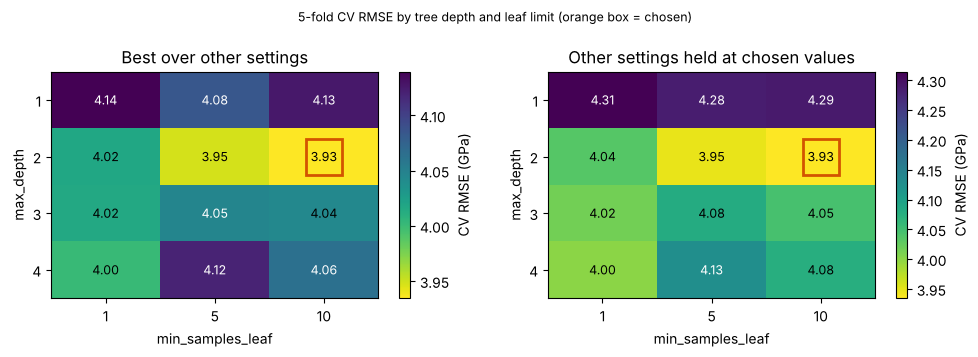

In [3]:
others = {k: v for k, v in p.items() if k not in ('max_depth', 'min_samples_leaf')}
held = np.logical_and.reduce([cv[f'param_{k}'] == v for k, v in others.items()])
depth_leaf_best = cv.pivot_table(index='param_max_depth', columns='param_min_samples_leaf', values='RMSE', aggfunc='min')
depth_leaf_held = cv[held].pivot_table(index='param_max_depth', columns='param_min_samples_leaf', values='RMSE')
search_tr = GridSearchCV(GradientBoostingRegressor(random_state=SEED, **others),
                         {'max_depth': GRID['max_depth'], 'min_samples_leaf': GRID['min_samples_leaf']},
                         cv=KFold(5, shuffle=True, random_state=SEED), scoring='neg_root_mean_squared_error',
                         return_train_score=True, n_jobs=-1).fit(X(tr), tr.E_GPa.values)
depth_leaf_train = pd.DataFrame(search_tr.cv_results_).assign(RMSE=lambda r: -r.mean_train_score) \
  .pivot_table(index='param_max_depth', columns='param_min_samples_leaf', values='RMSE')
for t in (depth_leaf_best, depth_leaf_held, depth_leaf_train):
    t.index.name, t.columns.name = 'max_depth', 'min_samples_leaf'

print('CV RMSE (GPa), best over all other settings:'); print(depth_leaf_best.round(3).to_string())
print(f'\nCV RMSE (GPa), other settings held at chosen values {others}:'); print(depth_leaf_held.round(3).to_string())
print('\nTraining RMSE (GPa, mean over CV folds), same held settings:'); print(depth_leaf_train.round(3).to_string())
pd.concat({'cv_best_over_others': depth_leaf_best, 'cv_held': depth_leaf_held, 'train_held': depth_leaf_train}) \
  .to_csv('gbr_cv20_dl_depth_leaf_table.csv')

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for a, t, title in [(ax[0], depth_leaf_best, 'Best over other settings'), (ax[1], depth_leaf_held, 'Other settings held at chosen values')]:
    im = a.imshow(t.values, cmap='viridis_r', aspect='auto')
    a.set_xticks(range(t.shape[1]), t.columns); a.set_yticks(range(t.shape[0]), t.index)
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            a.text(j, i, f'{t.values[i, j]:.2f}', ha='center', va='center', fontsize=9,
                   color='w' if t.values[i, j] > np.nanmean(t.values) else 'k')
    a.plot(GRID['min_samples_leaf'].index(p['min_samples_leaf']), GRID['max_depth'].index(p['max_depth']), 's',
           ms=26, mfc='none', mec='#d35400', mew=2)
    a.set(xlabel='min_samples_leaf', ylabel='max_depth', title=title); a.grid(False)
    fig.colorbar(im, ax=a, label='CV RMSE (GPa)')
fig.suptitle('5-fold CV RMSE by tree depth and leaf limit (orange box = chosen)', fontsize=9)
fig.tight_layout(); fig.savefig('gbr_cv20_dl_depth_leaf.png', dpi=150)
plt.show()

# Plotting block

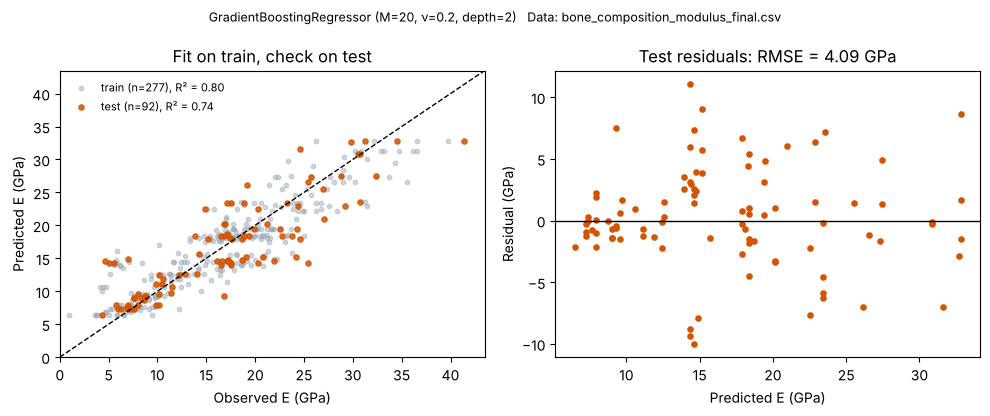

In [4]:
pd.DataFrame({'param': list(p) + ['cv_RMSE_GPa', 'importance_Ca', 'importance_Vf'],
              'value': list(p.values()) + [-search.best_score_, *gbr.feature_importances_]}) \
  .to_csv(f'gbr_cv20_dl_params.csv', index=False)
pd.concat([tr.assign(set='train', E_pred=pred_tr), te.assign(set='test', E_pred=pred_te)]) \
  .to_csv(f'gbr_cv20_dl_predictions.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
lim = [0, max(d.E_GPa.max(), pred_tr.max()) * 1.05]
ax[0].scatter(tr.E_GPa, pred_tr, s=10, alpha=.45, color='#9aa7b5', label=f'train (n={len(tr)}), R² = {m_tr["R2"]:.2f}')
ax[0].scatter(te.E_GPa, pred_te, s=14, alpha=.85, color='#d35400', label=f'test (n={len(te)}), R² = {m_te["R2"]:.2f}')
ax[0].plot(lim, lim, 'k--', lw=1); ax[0].legend(frameon=False, fontsize=8)
ax[0].set(xlim=lim, ylim=lim, xlabel='Observed E (GPa)', ylabel='Predicted E (GPa)', title='Fit on train, check on test')
ax[1].scatter(pred_te, te.E_GPa - pred_te, s=14, color='#d35400'); ax[1].axhline(0, color='k', lw=1)
ax[1].set(xlabel='Predicted E (GPa)', ylabel='Residual (GPa)', title=f'Test residuals: RMSE = {m_te["RMSE"]:.2f} GPa')
fig.suptitle(f'GradientBoostingRegressor (M={p["n_estimators"]}, ν={p["learning_rate"]}, depth={p["max_depth"]})   Data: {DATA}', fontsize=9)
fig.tight_layout(); fig.savefig(f'gbr_cv20_dl.png', dpi=150)
plt.show()